# Capstone. Co3O4 and CoOOH for the oxygen evolution reaction

- Teaches the working order of the project of this repository, on a small scale: check the model on the bulk, cleave a surface with the project's own script, relax it, put `*OH` on it and compute one adsorption energy
    - The oxygen evolution reaction, OER, is the anode reaction of water electrolysis, and `*OH` is an OH group bound to the surface; `README.md` in this folder tells the project in one page
- Two bulk crystals in section 1, Co3O4 and CoOOH, and one surface in section 2, a symmetric Co3O4(1 0 0) slab of the kind the project builds now, with the model `mace` in every `mlip` command
- Before you start: modules 00 to 10 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - Module 11 is about running on a cluster and is not needed here
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
    - The model weights sit in `~/.cache/mace/` from step 10 of module 00, so nothing is downloaded here
- After this you can run the project's slab script and say what each of its outputs is, relax a slab with every atom free, place `*OH` on a site that a tool listed, assemble an adsorption energy whose every term was relaxed at the same settings, and say which of the settings of this notebook a project would take from its own `CANON.md` and not from here

### Before you run this for a project

- The values in this notebook are teaching values, chosen so it runs on a laptop in minutes
- In a project, the items below are decided by your supervisor and written in the project's `CANON.md`; they are never taken from a tool default
    - `B1` source of the bulk structure: this notebook reads the two files of the `structures` folder, which came from the Materials Project (`structures/README.md`); the project's rule is not recorded in `DECISIONS.md`, ask
    - `B2` bulk relaxation degrees of freedom: cell and atoms together (`--relax-cell`), with no symmetry constraint given; not recorded, ask
    - `S1` how a surface is cleaved: the project's script `gen_rs_slabs.py`, which calls pymatgen's `SlabGenerator`; the project records its settings and a pymatgen version that this notebook does not use, see `DECISIONS.md`
    - `S2` slab thickness: whatever the script's cut target produces, printed below in Å; not recorded, ask, and the minimum thickness rule of `E-p3` is pending
    - `S3` symmetry and stoichiometry of the slab: symmetric and not stoichiometric; recorded, see `DECISIONS.md`
    - `S4` which faces and terminations: the script builds one slab per distinct face and this notebook takes one of them; recorded, see `DECISIONS.md`
    - `S5` vacuum: 15 Å asked of the script, measured below; recorded, see `DECISIONS.md`
    - `S6` smallest in-plane vector: 7.5 Å is asked of the script and the lengths of the slab are printed below; settled in the group's master canon
    - `S7` slabs from the optimized bulk: the slab is cleaved from the bulk relaxed in section 1, with this model; settled in the group's master canon
    - `S8` frozen layers: none here, every atom is free; the master leaves the scheme to the project, and `E-p3` records all atoms free for the project's symmetric slabs
    - `S9` slab cells are never relaxed: no slab command here has `--relax-cell`; settled in the group's master canon
    - `A1` which adsorption sites are studied: the first on-top site over a surface Co that a tool lists, a teaching choice; not recorded, ask
    - `A2` binding mode and orientation: OH bound through its O, upright, a teaching choice; not recorded, ask
    - `C1` MLIP model and head: this notebook uses `mace` (MACE-MP-0); the project records `uma-s-1p2` with `--uma-task oc25`, `mace-mh-1` and `chgnet`, see `DECISIONS.md`
    - `C2` force convergence `fmax`: 0.02 eV/Å with `fire` and 400 steps for the bulk, 0.05 eV/Å with `bfgs` and 200 steps for everything else here; the project records 0.05 eV/Å with BFGS and 300 steps for all of them, see `DECISIONS.md`
    - `C3` one head per energy formula: every energy of the adsorption energy comes from `mace`, and `_validate_mace_head` in `cli/utils.py` of mliprun (lines 390 to 401) rejects `--mace-head` for a tag that does not start with `mace-mh-`, such as `mace`, so there is no head to choose here; settled in the group's master canon
    - `C4` the same `fmax` and optimizer for the relaxations that enter one energy diagram: the slab, the slab with `*OH` and the two molecules are all relaxed at 0.05 eV/Å with `bfgs`; settled in the group's master canon
    - `K1` `converged` is a label the tool writes: it is printed for every relaxation, settled in the group's master canon
    - `E-p2` symmetric Reuter-Scheffler slabs, `E-p3` all atoms free with a thickness rule still pending, `E-p4` the references of the electrochemical anchor: project items, recorded in `DECISIONS.md`
- If a value is not recorded, ask before running; the tool will not stop you

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This notebook runs the `mlip` command and one script from the terminal side, as modules 07 and 09 did, and reads the files they write
    - `work/` fills up as you go, one folder per calculation, and it sits next to this notebook in `projects/ew2gc/`
- `sys.path.insert(0, str(Path("../../scripts").resolve()))` puts the repository's `scripts` folder at the front of the list of folders Python searches, as in modules 05 to 10, so `from onboarding_structures import molecule_in_box` works
- `sys`, `pathlib`, `json`, `re`, `shutil`, `subprocess`, `textwrap`, `time` and `importlib.metadata` all come with Python
    - `version("mliprun")` gives the version of an installed package as text, and `pmg_core.__version__` is the version of pymatgen that the project's script prints in its own warning
- `numpy` is imported under the short name `np`, `pandas` under `pd` and `matplotlib.pyplot` under `plt`, as in earlier modules
- `Atoms`, `read`, `write`, `plot_atoms` and `AseAtomsAdaptor` are ASE and pymatgen tools of earlier modules, and `AdsorbateSiteFinder` is the site finder of module 05
    - `jmol_colors` comes from `ase.data.colors`, and it is the table of ASE's default atom colours that the figure of the slab with `*OH` uses
    - `get_distances` comes from `ase.geometry`; given a list of points and a list of atom positions it returns every distance between them, and the section on `*OH` uses it
- `MLIP = Path(sys.executable).parent / "mlip"` is the `mlip` command of this environment, and `sys.executable` is also the Python that runs the project's script
    - In the terminal you type `mlip` and `python` on their own, with the `mlip-mace` environment active, and that is what the command lines printed below show
- `run_command(shown, argv, label)` runs one command, prints it as you would type it and how long it took, stops the notebook if the command failed, and keeps the time in `TIMES`
    - `run_mlip(arguments, label)` is the same for an `mlip` command
- `shorten(text)`, `last_lines(text, n)` and `first_lines(text, n)` replace this computer's own folder names in a block of terminal output and keep its last or first `n` lines that carry anything; nothing else is changed
- `last_stage(folder)` reads `mliprun_run.json` in a folder and returns its last stage, the record of the most recent run in that folder

In [1]:
import json
import re
import shutil
import subprocess
import sys
import textwrap
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymatgen.core as pmg_core
from ase import Atoms
from ase.data.colors import jmol_colors
from ase.geometry import get_distances
from ase.io import read, write
from ase.visualize.plot import plot_atoms
from pymatgen.analysis.adsorption import AdsorbateSiteFinder
from pymatgen.io.ase import AseAtomsAdaptor

sys.path.insert(0, str(Path("../../scripts").resolve()))
from onboarding_structures import molecule_in_box

WORK = Path("work")
WORK.mkdir(exist_ok=True)
STRUCTURES = Path("../../structures")
EXAMPLES = Path("examples")

MLIP = Path(sys.executable).parent / "mlip"
HERE = Path.cwd()
ENVIRONMENT = Path(sys.executable).parent.parent
HOME = Path.home()
TIMES = []


def shorten(text):
    # Replace this computer's own folder names in a block of terminal output.
    return (text.replace(str(HERE) + "/", "")
                .replace(str(ENVIRONMENT), "<environment>")
                .replace(str(HOME), "~"))


def last_lines(text, n):
    # The last n lines of a block of output that carry anything.
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[-n:])


def first_lines(text, n):
    # The first n lines of a block of output that carry anything.
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[:n])


def run_command(shown, argv, label, show=True):
    # Run one command from this folder, keep its time, and return the result.
    if show:
        print("Command, as you would type it in the terminal")
        print(shown)
    started = time.perf_counter()
    result = subprocess.run(argv, capture_output=True, text=True)
    seconds = time.perf_counter() - started
    TIMES.append({"command": label, "seconds": round(seconds, 1)})
    if show:
        print()
        print("Seconds the command took")
        print(round(seconds, 1))
    if result.returncode != 0:
        print()
        print("The command failed, and this is the end of what it wrote to its error stream")
        print(last_lines(result.stderr, 15))
        raise SystemExit("command failed")
    return result


def run_mlip(arguments, label, show=True):
    return run_command(" ".join(["mlip"] + arguments), [str(MLIP)] + arguments, label, show)


def last_stage(folder):
    # The last stage of the run record mliprun wrote in that folder.
    record = json.loads((Path(folder) / "mliprun_run.json").read_text())
    return record["stages"][-1]


print("Folder this notebook writes into")
print(WORK)
print("The mlip command of this environment was found")
print(MLIP.exists())
print("Version of mliprun")
print(version("mliprun"))
print("Version of pymatgen, as the project's script prints it")
print(pmg_core.__version__)

Folder this notebook writes into
work
The mlip command of this environment was found
True
Version of mliprun
0.4.0
Version of pymatgen, as the project's script prints it
2026.8.30


## 1. Validate the model on the bulk

- The surface of section 2 is cleaved from the bulk that this section relaxes, canon `S7`, so the lattice found here sets the size of every slab below
    - So the model is first run on the two bulk crystals of the project and the answer is put next to what the project recorded with its own models
- The first relaxation is Co3O4, the 56-atom conventional cell of `structures/Co3O4_mp-18748.vasp`, the cell the slab script will read
- The command, as you would type it from the folder of this notebook with the `mlip-mace` environment active:
    - `mlip optimize run --structure work/bulk_Co3O4/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400`
- `--relax-cell` is the one option of this command that earlier modules did not use, canon `B2`
    - The command hands the optimizer ASE's cell filter wrapped around the atoms, so the cell vectors move as well as the atoms (`core/optimize.py` of mliprun, lines 531 to 533 of the version printed above)
    - The `fmax(eV/A)` column of `opt_convergence.csv` is the largest force of that wrapped object (line 550), so on a `--relax-cell` run it includes the force-like terms of the cell and not the atomic forces alone
    - The file `opt_final.vasp` is written from the atoms after the run, so it holds the relaxed cell (line 651)
- These values are the course's teaching values for a bulk and they differ from the project's recorded `C2`
    - `--fmax 0.02`, `--optimizer fire` and `--max-steps 400` here, against 0.05 eV/Å, BFGS and 300 steps in `C2`, which the project applies to bulk, slabs and references alike
    - A project calculation uses `C2`, and `DECISIONS.md` has the entry
- What is read back from the folder after the run
    - `read(path)` loads a structure, `atoms.cell.cellpar()` gives the six cell parameters, three lengths in Å and three angles in degrees, and `atoms.get_volume()` gives the cell volume in Å3
    - `len(atoms)` is the number of atoms, and the number of formula units is that number divided by the atoms in one formula unit: 7 for Co3O4
    - The run record gives the steps, the `converged` label and the final largest force, canon `K1`, as in modules 07 and 09
    - `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in earlier modules, and `round(x, n)` rounds a number to `n` decimals
- The error stream of this command carries warning lines, and the cell counts one kind of them
    - They come from `logm`, the matrix-logarithm routine of scipy that ASE's `FrechetCellFilter` loads (`ase/filters.py`, line 577), and each one prints a tiny approximate error
    - The cell prints how many such lines there are and the last one; this notebook does not test what they mean, and reads the `converged` label and the force of the run record instead
- The Co3O4 file holds no magnetic moments
    - The cell prints the first eight lines of `work/bulk_Co3O4/POSCAR`, which are the title, the scale, the three cell vectors, the elements, their counts and the word `direct`, and then the set of the numbers of fields of the coordinate lines below them
    - A set of 4 means each coordinate line holds three coordinates and an element symbol, so there is no column for a moment; and no option of `mlip optimize run` sets one either (the option list of `cli/commands/optimize.py` of mliprun, lines 259 to 303)
    - So this notebook says nothing about the magnetic order of the Co atoms, and what the project's DFT uses is not in `DECISIONS.md`; it is a decision of your supervisor

In [2]:
FU_ATOMS = {"Co3O4": 7, "CoOOH": 4}
BULK_CO3O4 = WORK / "bulk_Co3O4"
BULK_CO3O4.mkdir(exist_ok=True)
shutil.copy(STRUCTURES / "Co3O4_mp-18748.vasp", BULK_CO3O4 / "POSCAR")

result = run_mlip(["optimize", "run",
                   "--structure", str(BULK_CO3O4 / "POSCAR"),
                   "--mlip", "mace",
                   "--device", "cpu",
                   "--relax-cell",
                   "--fmax", "0.02",
                   "--optimizer", "fire",
                   "--max-steps", "400"], "bulk Co3O4, cell and atoms")

co3o4_before = read(BULK_CO3O4 / "POSCAR")
co3o4_after = read(BULK_CO3O4 / "opt_final.vasp")
stage_co3o4 = last_stage(BULK_CO3O4)
logm = [line for line in result.stderr.splitlines() if "logm result may be inaccurate" in line]


def cell_row(label, atoms, material):
    a, b, c, alpha, beta, gamma = atoms.cell.cellpar()
    n_fu = len(atoms) // FU_ATOMS[material]
    return {"structure": label, "a (Å)": round(a, 4), "b (Å)": round(b, 4), "c (Å)": round(c, 4),
            "alpha (°)": round(alpha, 2), "beta (°)": round(beta, 2), "gamma (°)": round(gamma, 2),
            "volume per formula unit (Å3)": round(atoms.get_volume() / n_fu, 3)}


print()
print("Atoms in the cell")
print(len(co3o4_after))
print("Status of the last stage in the run record")
print(stage_co3o4["status"])
print("converged, from the last stage's results")
print(stage_co3o4["results"]["converged"])
print("Steps")
print(stage_co3o4["steps"])
print("Final largest force of the cell filter (eV/Å)")
print(round(stage_co3o4["results"]["final_fmax_eV_per_A"], 4))
print("Final energy (eV)")
print(round(stage_co3o4["results"]["final_energy_eV"], 3))
print()
print("Lines of the error stream that carry 'logm result may be inaccurate'")
print(len(logm))
print("The last of them")
print(shorten(logm[-1]).strip() if logm else "none")
print()
print("Co3O4 cell before and after")
print(pd.DataFrame([cell_row("as served", co3o4_before, "Co3O4"),
                    cell_row("relaxed", co3o4_after, "Co3O4")]).to_string(index=False))

poscar_lines = (BULK_CO3O4 / "POSCAR").read_text().splitlines()
print()
print("First eight lines of work/bulk_Co3O4/POSCAR")
print("\n".join(poscar_lines[:8]))
print("Number of fields in each coordinate line, as a set")
print({len(line.split()) for line in poscar_lines[8:] if line.strip()})

Command, as you would type it in the terminal
mlip optimize run --structure work/bulk_Co3O4/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400



Seconds the command took
8.8

Atoms in the cell
56
Status of the last stage in the run record
converged
converged, from the last stage's results
True
Steps
18
Final largest force of the cell filter (eV/Å)
0.0176
Final energy (eV)
-336.508

Lines of the error stream that carry 'logm result may be inaccurate'
17
The last of them
<environment>/lib/python3.11/site-packages/scipy/_lib/_util.py:1181: RuntimeWarning: logm result may be inaccurate, approximate err = 5.631231728879823e-13

Co3O4 cell before and after
structure  a (Å)  b (Å)  c (Å)  alpha (°)  beta (°)  gamma (°)  volume per formula unit (Å3)
as served 8.0459 8.0459 8.0459       90.0      90.0       90.0                        65.107
  relaxed 8.1694 8.1694 8.1694       90.0      90.0       90.0                        68.154

First eight lines of work/bulk_Co3O4/POSCAR
Co24 O32
1.0
   8.0458686010508682    0.0000000000000000    0.0000000000000005
  -0.0000000000000005    8.0458686010508682    0.0000000000000005
   0.00000000000

### 1a. CoOOH

- CoOOH, `structures/CoOOH_mp-27913.vasp`, is a 4-atom cell with one formula unit, relaxed with the same command into `work/bulk_CoOOH/`
    - `mlip optimize run --structure work/bulk_CoOOH/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400`
- The H atom of this file sits exactly midway between its two O neighbours, at fractional position 0.5, 0.5, 0.5, as `structures/README.md` says
    - That is a symmetric arrangement, with the H on the line between the two O atoms and equally far from both, and the next two sections test whether the model keeps it
- `atoms.get_distances(i, indices, mic=True)` gives the distances from atom `i` to a list of atoms, taking the shortest way across the periodic boundary, as in module 05
    - `array.round(n)` rounds every number of a NumPy array to `n` decimals, which the cells of this notebook use to print arrays
    - `np.sort(array)` puts them in increasing order, so the first is the O the H is nearer to and the second is the other
    - The cell prints them before and after the relaxation, with the O to O distance, which is `atoms.get_distance(i, j, mic=True)`, the distance between two atoms
    - `.index("H")` on the list of chemical symbols gives the position of the H atom, and a list of the positions whose symbol is `"O"` gives the two O atoms
- In the saved run:
    - The two H to O distances are 1.199 Å in the file and 1.205 Å after the relaxation, so the H stays midway between its two O atoms, and the O to O distance after it is 2.41 Å
    - What this page can say about that is limited to this run: a relaxation from a symmetric start did not leave the symmetric arrangement, and it converged by its label; nothing here says yet whether that arrangement is the lowest one, and the next section tests it with a different start

In [3]:
BULK_COOOH = WORK / "bulk_CoOOH"
BULK_COOOH.mkdir(exist_ok=True)
shutil.copy(STRUCTURES / "CoOOH_mp-27913.vasp", BULK_COOOH / "POSCAR")

run_mlip(["optimize", "run",
          "--structure", str(BULK_COOOH / "POSCAR"),
          "--mlip", "mace",
          "--device", "cpu",
          "--relax-cell",
          "--fmax", "0.02",
          "--optimizer", "fire",
          "--max-steps", "400"], "bulk CoOOH, as served")

coooh_before = read(BULK_COOOH / "POSCAR")
coooh_after = read(BULK_COOOH / "opt_final.vasp")
stage_coooh = last_stage(BULK_COOOH)


def hydrogen_bond(atoms):
    # Distances from the H atom to the two O atoms, nearer first, and the O to O distance.
    symbols = atoms.get_chemical_symbols()
    h = symbols.index("H")
    o = [i for i, s in enumerate(symbols) if s == "O"]
    return np.sort(atoms.get_distances(h, o, mic=True)), atoms.get_distance(o[0], o[1], mic=True)


print()
print("Status of the last stage, converged, steps")
print([stage_coooh["status"], stage_coooh["results"]["converged"], stage_coooh["steps"]])
print("Final largest force of the cell filter (eV/Å)")
print(round(stage_coooh["results"]["final_fmax_eV_per_A"], 4))
print("Final energy (eV)")
print(round(stage_coooh["results"]["final_energy_eV"], 4))
print()
print("H to its two O atoms in the file (Å), nearer first")
print(hydrogen_bond(coooh_before)[0].round(3))
print("H to its two O atoms after the relaxation (Å), nearer first")
print(hydrogen_bond(coooh_after)[0].round(3))
print("O to O distance after the relaxation (Å)")
print(round(float(hydrogen_bond(coooh_after)[1]), 3))
print()
print("CoOOH cell before and after")
print(pd.DataFrame([cell_row("as served", coooh_before, "CoOOH"),
                    cell_row("relaxed from the file", coooh_after, "CoOOH")]).to_string(index=False))

Command, as you would type it in the terminal
mlip optimize run --structure work/bulk_CoOOH/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400



Seconds the command took
4.6

Status of the last stage, converged, steps
['converged', True, 13]
Final largest force of the cell filter (eV/Å)
0.018
Final energy (eV)
-22.1512

H to its two O atoms in the file (Å), nearer first
[1.199 1.199]
H to its two O atoms after the relaxation (Å), nearer first
[1.205 1.205]
O to O distance after the relaxation (Å)
2.41

CoOOH cell before and after
            structure  a (Å)  b (Å)  c (Å)  alpha (°)  beta (°)  gamma (°)  volume per formula unit (Å3)
            as served 4.6148 4.6148 4.6148      35.96     35.96      35.96                        30.306
relaxed from the file 4.6727 4.6727 4.6727      35.85     35.85      35.85                        31.284


### 1b. CoOOH with the H atom moved

- The same crystal and the same command, from a start where the H atom is moved 0.3 Å along the line to one of its two O atoms, into `work/bulk_CoOOH_h/`
    - `mlip optimize run --structure work/bulk_CoOOH_h/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400`
    - The 0.3 Å is a teaching value; it only has to take the H off the symmetric position
- `atoms.get_distances(h, o, mic=True, vector=True)` returns the vectors from the H to each O instead of their lengths
    - `np.linalg.norm(vector)` is the length of a vector, and dividing the vector by it gives a vector of length 1, which is the direction
    - `atoms.positions[h] += 0.3 * direction` moves the H by 0.3 Å along that direction
    - `write(path, atoms, format="vasp", direct=True, sort=True)` saves the start in the form of module 07, as a `POSCAR` in its own folder
- The question this run answers is whether the symmetric answer of the section above is the only answer the model has, and it answers it for this start and this model
- In the saved run:
    - The relaxation ends with the H at 1.006 Å from one O and at 1.668 Å from the other, an O to O distance of 2.605 Å, and a volume per formula unit of 35.066 Å3 against 31.284 Å3 for the symmetric run
    - Its final energy is 0.0885 eV lower than the symmetric run's, for the 4-atom cell, so the symmetric arrangement is not the lowest-energy arrangement this model offers for this crystal
    - Both runs converged by their label, so a `converged` label alone did not tell them apart; the start did
    - Whether a third start would find a still lower one is not tested on this page

In [4]:
BULK_COOOH_H = WORK / "bulk_CoOOH_h"
BULK_COOOH_H.mkdir(exist_ok=True)

moved = read(BULK_COOOH / "POSCAR")
symbols = moved.get_chemical_symbols()
h_index = symbols.index("H")
o_index = [i for i, s in enumerate(symbols) if s == "O"]
vectors = moved.get_distances(h_index, o_index, mic=True, vector=True)
direction = vectors[0] / np.linalg.norm(vectors[0])
moved.positions[h_index] += 0.3 * direction
write(BULK_COOOH_H / "POSCAR", moved, format="vasp", direct=True, sort=True)

print("H to its two O atoms in the start (Å)")
print(moved.get_distances(h_index, o_index, mic=True).round(3))
print()

run_mlip(["optimize", "run",
          "--structure", str(BULK_COOOH_H / "POSCAR"),
          "--mlip", "mace",
          "--device", "cpu",
          "--relax-cell",
          "--fmax", "0.02",
          "--optimizer", "fire",
          "--max-steps", "400"], "bulk CoOOH, H moved")

coooh_h_after = read(BULK_COOOH_H / "opt_final.vasp")
stage_coooh_h = last_stage(BULK_COOOH_H)

print()
print("Status of the last stage, converged, steps")
print([stage_coooh_h["status"], stage_coooh_h["results"]["converged"], stage_coooh_h["steps"]])
print("Final largest force of the cell filter (eV/Å)")
print(round(stage_coooh_h["results"]["final_fmax_eV_per_A"], 4))
print("Final energy (eV)")
print(round(stage_coooh_h["results"]["final_energy_eV"], 4))
print("Final energy minus the final energy of the symmetric run (eV)")
print(round(stage_coooh_h["results"]["final_energy_eV"] - stage_coooh["results"]["final_energy_eV"], 4))
print()
print("H to its two O atoms after the relaxation (Å), nearer first")
print(hydrogen_bond(coooh_h_after)[0].round(3))
print("O to O distance after the relaxation (Å)")
print(round(float(hydrogen_bond(coooh_h_after)[1]), 3))
print()
print("CoOOH cell, the three states")
print(pd.DataFrame([cell_row("as served", coooh_before, "CoOOH"),
                    cell_row("relaxed from the file", coooh_after, "CoOOH"),
                    cell_row("relaxed with the H moved", coooh_h_after, "CoOOH")]).to_string(index=False))

H to its two O atoms in the start (Å)
[0.899 1.499]

Command, as you would type it in the terminal
mlip optimize run --structure work/bulk_CoOOH_h/POSCAR --mlip mace --device cpu --relax-cell --fmax 0.02 --optimizer fire --max-steps 400



Seconds the command took
6.1

Status of the last stage, converged, steps
['converged', True, 53]
Final largest force of the cell filter (eV/Å)
0.0197
Final energy (eV)
-22.2397
Final energy minus the final energy of the symmetric run (eV)
-0.0885

H to its two O atoms after the relaxation (Å), nearer first
[1.006 1.668]
O to O distance after the relaxation (Å)
2.605

CoOOH cell, the three states
               structure  a (Å)  b (Å)  c (Å)  alpha (°)  beta (°)  gamma (°)  volume per formula unit (Å3)
               as served 4.6148 4.6148 4.6148      35.96     35.96      35.96                        30.306
   relaxed from the file 4.6727 4.6727 4.6727      35.85     35.85      35.85                        31.284
relaxed with the H moved 4.9475 4.9475 4.9475      34.72     34.72      34.72                        35.066


### 1c. Against what the project recorded

- The table puts this notebook's numbers next to the values the project recorded with its own models, each traced to a file of the project folder
    - Co3O4 lattice parameter, uma-s with the `oc25` head, 8.0675 Å: `calculations/explicit_solvation/PRODUCTION/00_bulk/Co3O4_bulk/uma-s/README.md`, and line 55 of `calculations/explicit_solvation/PHASE5_SPEC.md`
    - Co3O4, `mace-mh-1` with the `omat_pbe` head, 8.1698 Å, and `chgnet`, 8.1651 Å: lines 56 and 57 of `PHASE5_SPEC.md`, under the heading of a full cell relaxation
    - CoOOH, MACE-MP-0: "+18 % volume with a stretched hydrogen-bond network (1.69 Å)", and `mace-mh-1` within 0.05 Å of the UMA and CHGNet structure: line 17 of `calculations/explicit_solvation/PLAN.md` and line 13 of `calculations/explicit_solvation/PROJECT_RECAP_2026-05-12.md`
- What each comparison can and cannot say
    - Every reference above is the result of a machine-learning model run by the project, MACE-MP-0 itself for the CoOOH note, and none of them is a DFT or an experimental value printed on this page, so agreement with them is agreement between models and not a validation against nature
    - Reading list Part A, entry 6, the review of machine-learning force fields, is where the failure modes of these models are described, and agreement among models does not show that none of them fails
    - The project's lines do not say what the +18 % is measured against or which starting structure produced it, so the volume change printed below is measured against the file of this repository and is not a like-for-like copy of that number
- In the cell below, `table["new column"] = (...)` adds a column to a table, and `.round(4)` on a column rounds every value in it to four decimals
- In the table:
    - The rows of this notebook and of the file as served are read from files, and the three project rows are typed in with their source, so the difference column is computed and the references are not
    - The MACE-MP-0 lattice parameter, 8.1694 Å, is within 0.001 Å of the project's `mace-mh-1` value and 0.1019 Å above the project's canonical uma-s value, which is 1.26 % in length
    - The project's `C1` models are not this notebook's model, which is why a project run does not take its numbers from here
- What the two CoOOH runs say together
    - From the file as served the volume per formula unit grows by 3.2 %, from the moved start by 15.7 %, against the +18 % of the project's note
    - The H to O distance of the longer side is 1.668 Å from the moved start, 0.02 Å below the project's 1.69 Å
    - So the answer of this model for CoOOH depends on the start the H is given, and a result quoted without its start is not reproducible
    - The project's note does not say which start its +18 % came from, so this page does not show that it came from a moved H; it shows that a moved H gives a number of that size with this model

In [5]:
a_relaxed = float(co3o4_after.cell.cellpar()[0])
a_project = 8.0675
rows = [{"Co3O4 lattice parameter a": "uma-s, oc25 head, canonical", "value (Å)": a_project,
         "source": "uma-s/README.md, PHASE5_SPEC.md line 55"},
        {"Co3O4 lattice parameter a": "mace-mh-1, omat_pbe head", "value (Å)": 8.1698,
         "source": "PHASE5_SPEC.md line 56"},
        {"Co3O4 lattice parameter a": "chgnet", "value (Å)": 8.1651,
         "source": "PHASE5_SPEC.md line 57"},
        {"Co3O4 lattice parameter a": "MACE-MP-0, this notebook", "value (Å)": round(a_relaxed, 4),
         "source": "work/bulk_Co3O4/opt_final.vasp"},
        {"Co3O4 lattice parameter a": "the file as served", "value (Å)": round(float(co3o4_before.cell.cellpar()[0]), 4),
         "source": "structures/Co3O4_mp-18748.vasp"}]
table = pd.DataFrame(rows)
table["minus the uma-s value (Å)"] = (table["value (Å)"] - a_project).round(4)
print("Co3O4, this notebook against the values the project recorded")
print(table.to_string(index=False))

print()
print("Length change of a, MACE-MP-0 against the uma-s value (%)")
print(round((a_relaxed / a_project - 1) * 100, 2))

v0 = coooh_before.get_volume()
rows = []
for label, atoms in (("from the file as served", coooh_after), ("with the H moved", coooh_h_after)):
    near_far, _ = hydrogen_bond(atoms)
    rows.append({"CoOOH, MACE-MP-0, this notebook": label,
                 "volume against the file (%)": round((atoms.get_volume() / v0 - 1) * 100, 1),
                 "longer H to O distance (Å)": round(float(near_far[1]), 3)})
rows.append({"CoOOH, MACE-MP-0, this notebook": "the project's note, PLAN.md line 17",
             "volume against the file (%)": 18.0,
             "longer H to O distance (Å)": 1.69})
print()
print("CoOOH, this notebook against the project's note")
print(pd.DataFrame(rows).to_string(index=False))

Co3O4, this notebook against the values the project recorded
  Co3O4 lattice parameter a  value (Å)                                  source  minus the uma-s value (Å)
uma-s, oc25 head, canonical     8.0675 uma-s/README.md, PHASE5_SPEC.md line 55                     0.0000
   mace-mh-1, omat_pbe head     8.1698                  PHASE5_SPEC.md line 56                     0.1023
                     chgnet     8.1651                  PHASE5_SPEC.md line 57                     0.0976
   MACE-MP-0, this notebook     8.1694          work/bulk_Co3O4/opt_final.vasp                     0.1019
         the file as served     8.0459          structures/Co3O4_mp-18748.vasp                    -0.0216

Length change of a, MACE-MP-0 against the uma-s value (%)
1.26

CoOOH, this notebook against the project's note
    CoOOH, MACE-MP-0, this notebook  volume against the file (%)  longer H to O distance (Å)
            from the file as served                          3.2                       1.205
    

## 2. Cleave Co3O4(1 0 0) the project's way

- The project builds its Co3O4 surfaces with `gen_rs_slabs.py`, copied into `examples/` with a provenance header; the project's own file is the authoritative one, and `examples/README.md` says what else came with it
    - Canon `S1`, `S3`, `S4`, `S5` and `E-p2`, `E-p3` of `DECISIONS.md` are the entries behind what it does
- The command, as you would type it from the folder of this notebook with the `mlip-mace` environment active:
    - `python examples/gen_rs_slabs.py --bulk work/bulk_Co3O4/opt_final.vasp --mlip mace --miller 1 0 0 --output-base work/slabs --skip-prod-map --sym-target-A 10 --min-area-A2 60 --vacuum 15 --min-axis-A 7.5`
- What the options do, read from the script
    - `--bulk` is the relaxed bulk of section 1, canon `S7`; this is why the slab size follows from this model's lattice
    - `--mlip mace` is only a label: the script uses it in a printed line, in the audit table and in the name of the output folder, and it imports no model code, so it does not take the place of `--mlip mace` in an `mlip` command (`examples/gen_rs_slabs.py`, lines 400, 413, 494 and 509)
    - `--miller 1 0 0` is the face to cut, and `--output-base` is where the slabs and the audit table go
    - `--skip-prod-map` leaves out a comparison with the labels of the project's earlier production slabs (line 371); that comparison calls a function of a module from the group's `compcatalysis-skills` repository, and `examples/README.md` says what this repository puts in its place
    - `--vacuum 15` is the vacuum the script asks of pymatgen's `SlabGenerator` as `min_vacuum_size`, canon `S5` (lines 207 and 391), and the section on the slab this notebook takes measures it
    - `--min-axis-A 7.5` is canon `S6`, the smallest in-plane vector; `--min-area-A2 60` is a teaching value, the smallest in-plane area of the cell, which the script's default of 100 would turn into a larger cell
    - `--sym-target-A 10` is a teaching value for the thickness of the first cut the script tries, and it goes up in steps of 4 Å when the trimming fails, so the thickness you get is the one the output reports and not the number you typed (lines 298, 300 and 432 to 449); the rule that sets the project's minimum thickness is still pending, `E-p3`
- The script's own warning about pymatgen is shown on the page
    - Canon `S1` pins pymatgen to 2025.6.14 or older, and this environment has a newer one, so the script prints a warning that the set of cuts and the numbering of faces may differ from production
    - A project environment uses the pinned version; the labels `r0` to `r3` here may not match the project's
- The return code of the script is 0 when every face it built is ok (line 520), and the cell stops the notebook on any other
- In the saved run:
    - The warning is the first line of the output, and the next line names two settings the script took from its own defaults for Co3O4, `ftol=0.005` and an empty bond rule; `ftol` is handed to pymatgen's `get_slabs` (line 209), and canon `S1` records its value
    - The script found 16 stoichiometric cuts and 4 distinct faces, `r0` to `r3`, labels given in the order the script met the face classes, and for each of the four faces the trimming failed at the cut targets of 10 Å and 14 Å before it worked
    - Each face has a line that begins with `[EDGE]`: the script prints it when the area of the tiled cell, 67 Å2 here, is within 8 Å2 of the area asked for, 60 Å2 (`compute_supercell_mult` of `examples/gen_slabs.py`)

In [6]:
SLAB_BASE = WORK / "slabs"
result = run_command("python examples/gen_rs_slabs.py --bulk work/bulk_Co3O4/opt_final.vasp --mlip mace "
                     "--miller 1 0 0 --output-base work/slabs --skip-prod-map --sym-target-A 10 "
                     "--min-area-A2 60 --vacuum 15 --min-axis-A 7.5",
                     [sys.executable, str(EXAMPLES / "gen_rs_slabs.py"),
                      "--bulk", str(BULK_CO3O4 / "opt_final.vasp"),
                      "--mlip", "mace",
                      "--miller", "1", "0", "0",
                      "--output-base", str(SLAB_BASE),
                      "--skip-prod-map",
                      "--sym-target-A", "10",
                      "--min-area-A2", "60",
                      "--vacuum", "15",
                      "--min-axis-A", "7.5"], "gen_rs_slabs.py, Co3O4(1 0 0)")

print()
print("Everything the script printed, with the local folder names replaced")
print(shorten(result.stdout).strip())

Command, as you would type it in the terminal
python examples/gen_rs_slabs.py --bulk work/bulk_Co3O4/opt_final.vasp --mlip mace --miller 1 0 0 --output-base work/slabs --skip-prod-map --sym-target-A 10 --min-area-A2 60 --vacuum 15 --min-axis-A 7.5



Seconds the command took
3.7

Everything the script printed, with the local folder names replaced
[WARN] pymatgen 2026.8.30 > 2025.6.14: cut set and f<N> numbering may differ from production (S1).
Settings: ftol=0.005 (canon default), keep_bonds=[] (canon default)
Co3O4 mace (100): 16 stoichiometric cuts, 0 production f<N>, 4 distinct faces (depth 4.0 A), ref element Co, pymatgen 2026.8.30
  r0: Co3[2]|Co5.99[5]_O5.99[3]_O5.99[4]|Co3[4]|Co5.99[6]_O11.99[4]  production faces: -
    trimming failed at cut target 10 A; thicker cut
    trimming failed at cut target 14 A; thicker cut
    [EDGE] r0 2x1: area=67 Å² is within 8 Å² of the 60 Å² target
    -> Co68O88 2x1, 22.466 A, excess O=-2.667, trimmed 6, status ok
  r1: Co5.99[5]_O11.99[3]|Co3[4]|Co5.99[6]_O11.99[4]|Co3[4]  production faces: -
    trimming failed at cut target 10 A; thicker cut
    trimming failed at cut target 14 A; thicker cut
    [EDGE] r1 2x1: area=67 Å² is within 8 Å² of the 60 Å² target
    -> Co70O96 2x1, 22.708 A, 

### 2a. The faces

- The script writes an audit table, `rs_slabs_audit.csv`, with one row per distinct face, and the slab of each face in its own folder, `work/slabs/Co3O4/mace/100_r<k>/POSCAR`
    - `pd.read_csv(path)` reads the table, and `table[["a", "b"]]` with double brackets keeps the columns named in the inner list
    - `table["column"].str.split("|").str[0]` cuts every text of a column at each `|` and keeps the first piece, which is how the third table takes the outermost layer out of a face key
- A symmetric slab exposes the same face on both sides, so its surface energy belongs to that face alone
    - That is why the project enumerates faces and not cuts: every cut has a top and a bottom face, both are collected and grouped into face classes, and each class is built once (canon `S4`)
    - The audit columns `is_symmetric_pmg`, `faces_match` and `doubled_face_ok` are the script's own checks that the slab is symmetric, that its two faces have the same fingerprint, and that the doubled face is the face that was asked for
- The surface energy of such a slab is a line in the oxygen chemical potential `μ_O`, and it is not computed on this page
    - `E-p2` gives it as `γ(μ_O) = [E_slab − (N_Co/3)·E_bulk_fu + ((4/3)·N_Co − N_O)·μ_O]/(2A)`, with `N_Co` and `N_O` the numbers of Co and O atoms of the slab, `E_bulk_fu` the energy of one Co3O4 formula unit and `A` the area of one face
    - The `excess` column is `N_O − (4/3)·N_Co`, the O atoms the slab holds beyond those of a stoichiometric slab with the same Co (`chemistry` in the script), and it is the minus of the `μ_O` coefficient of `E-p2`
    - A face with zero excess would have a surface energy that does not depend on `μ_O`, as `S3` of `DECISIONS.md` says of a symmetric stoichiometric cut
    - Lines with different slopes cross, and `E-p2` says the exposed termination is set by thermodynamics and not by a selection rule; so the project builds every face and lets `γ(μ_O)` decide, canon `S4`, and does not pick one face by hand
- Which face this notebook takes is a teaching choice and not a result
    - The notebook takes `r1`, because its outermost layer holds Co atoms with 5 neighbours each, against 2 in `r0` and 3 in `r3`, while the outermost layer of `r2` holds no Co; that is a reason to have a Co site to put an OH on, and it is not a ranking
    - No energy on this page ranks the four faces
- In the second table, the three columns are the script's checks named above, and every row reads `True`
- In the first table
    - `n_cuts_with_face` is how many of the 16 cuts carry that face on one side or the other, and `n_trimmed` is the number of atoms the script removed to make the slab symmetric
    - `lateral_label` is how many times the in-plane cell was repeated, `sym_target_A` is the cut thickness in Å at which the trimming worked, and `actual_A` is the thickness of the slab in Å, measured along z
- In the third table, each layer of a face key is written as a list of `element[number of neighbours within 2.2 Å]` with the number of atoms of that kind per 100 Å2 of the face, and the layers are listed from the outermost one down; the cutoff of 2.2 Å is the script's `--cn-cutoff-A`
    - The table shows the outermost layer only

In [7]:
audit = pd.read_csv(SLAB_BASE / "rs_slabs_audit.csv")

print("Faces the script found, one row each")
print(audit[["face_label", "status", "n_cuts_with_face", "n_trimmed", "n_atoms", "composition",
             "excess", "lateral_label", "area_A2", "sym_target_A", "actual_A"]].to_string(index=False))

print()
print("The script's own checks, one row per face")
print(audit[["face_label", "is_symmetric_pmg", "faces_match", "doubled_face_ok"]].to_string(index=False))

print()
print("Outermost layer of each face, from its face key")
outer = pd.DataFrame({"face": audit["face_label"],
                      "outermost layer": audit["face_key"].str.split("|").str[0]})
print(outer.to_string(index=False))

Faces the script found, one row each
face_label status  n_cuts_with_face  n_trimmed  n_atoms composition   excess lateral_label  area_A2  sym_target_A  actual_A
        r0     ok                 8          6      156     Co68O88 O=-2.667           2x1    66.74          18.0    22.466
        r1     ok                 8          1      166     Co70O96 O=+2.667           2x1    66.74          18.0    22.708
        r2     ok                 8          2      164     Co68O96 O=+5.333           2x1    66.74          18.0    24.266
        r3     ok                 8          5      158     Co70O88 O=-5.333           2x1    66.74          18.0    22.466

The script's own checks, one row per face
face_label  is_symmetric_pmg  faces_match  doubled_face_ok
        r0              True         True             True
        r1              True         True             True
        r2              True         True             True
        r3              True         True             True

Oute

### 2b. The slab this notebook takes

- The slab of face `r1`, `work/slabs/Co3O4/mace/100_r1/POSCAR`, is read and checked before anything is run on it
    - `atoms.get_chemical_formula()` is the composition, `atoms.cell.lengths()` are the three cell lengths, and `atoms.positions[:, 2]` is the z coordinate of every atom
    - `array.max()` and `array.min()` are the largest and the smallest value of a NumPy array
    - The thickness is the largest z minus the smallest, and the vacuum gap is the length of the third cell vector minus the thickness
- The checks, each against what the project records
    - In-plane lengths of at least 7.5 Å, canon `S6`: the saved run has 11.553 Å and 8.169 Å, at an angle of 135°, and the area is the 66.74 Å2 the table above lists
    - A vacuum gap of at least the 15 Å asked of the script, canon `S5`: the gap measured on the file is 18.139 Å, so it meets the request, and this page does not trace why it is larger than 15 Å
    - All atoms free, `E-p3`: the file has no selective-dynamics flags and ASE reads no constraints from it, and the cell prints both
- The thickness is whatever the script's trimming gave, 22.708 Å, and the project's own minimum thickness rule is pending, `E-p3`; the validator that `E-p3` asks for, a check that the central interlayer spacings are bulk-like, is not run in this notebook
- In the figure:
    - A side view of the slab as the script wrote it, with `ax.set_ylim(low, high)` cutting the vertical range to the atoms plus 3 Å on each side, so only part of the vacuum is drawn
    - The large pink atoms are Co and the small red atoms are O

Face taken
r1
Atoms in the slab
166
Composition
Co70O96

In-plane cell lengths a and b (Å)
[11.553  8.169]
Angle between a and b (°)
135.0
Third cell vector (Å)
[ 0.     0.    40.847]
Thickness of the slab, largest z minus smallest z (Å)
22.708
Vacuum gap, c minus the thickness (Å)
18.139

The word 'Selective' in the POSCAR the script wrote
False
Constraints ASE reads from it
0


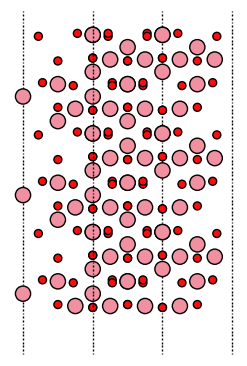

In [8]:
FACE = "r1"
slab_dir = SLAB_BASE / "Co3O4" / "mace" / ("100_" + FACE)
slab = read(slab_dir / "POSCAR")
poscar_text = (slab_dir / "POSCAR").read_text()
z = slab.positions[:, 2]
lengths = slab.cell.lengths()
thickness = float(z.max() - z.min())

print("Face taken")
print(FACE)
print("Atoms in the slab")
print(len(slab))
print("Composition")
print(slab.get_chemical_formula())
print()
print("In-plane cell lengths a and b (Å)")
print(lengths[:2].round(3))
print("Angle between a and b (°)")
print(round(float(slab.cell.cellpar()[5]), 1))
print("Third cell vector (Å)")
print(slab.cell[2].round(3))
print("Thickness of the slab, largest z minus smallest z (Å)")
print(round(thickness, 3))
print("Vacuum gap, c minus the thickness (Å)")
print(round(float(lengths[2]) - thickness, 3))
print()
print("The word 'Selective' in the POSCAR the script wrote")
print("Selective" in poscar_text)
print("Constraints ASE reads from it")
print(len(slab.constraints))

fig, ax = plt.subplots(figsize=(3.2, 4.5))
plot_atoms(slab, ax, radii=0.5, rotation="-90x")
ax.set_ylim(z.min() - 3, z.max() + 3)
plt.show()

## 3. Relax the clean slab

- The slab file is copied into its own folder, `work/slab_clean/`, so that the files of the run do not land among the script's outputs, and relaxed
    - `mlip optimize run --structure work/slab_clean/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200`
- The settings
    - No `--relax-cell`: the slab cell is never relaxed, canon `S9`, so its in-plane lengths are the ones of the bulk of section 1
    - All atoms free, canon `E-p3`; the file carries no flags, so the command has nothing to hold fixed
    - The Pt(1 1 1) slab of the earlier modules has its bottom layer fixed (`pt111_slab`), and this slab does not
    - The project's reason, `E-p3`: frozen atoms are the artifact of the earlier route that the project is leaving, and freeing every atom adds no relaxation depth that would depend on the face; in exchange `E-p3` asks for a check that the central interlayer spacings are bulk-like
    - Which layers to freeze on a slab of any other kind is a decision of the project, canon `S8`, which the master canon leaves open and which `DECISIONS.md` shows as not recorded
    - `--fmax 0.05`, `--optimizer bfgs` and `--max-steps 200` are named although they match this command's defaults, as in module 07, canon `C2`
- `pd.read_csv(path)` reads `opt_convergence.csv`, and `table["energy(eV)"].iloc[0]` is the first value of a column, which is the energy of step 0
- In the printed output:
    - The run record's `converged` label, the steps, the final force and the energy, canon `K1`
    - The energy of step 0, the structure as the script wrote it, taken from `opt_convergence.csv`, and the fall from it
    - The cell lengths before and after, which show that the cell did not change
- In the saved run:
    - The relaxation takes 9 steps and ends converged with a largest force of 0.0482 eV/Å, just under the target of 0.05
    - The energy falls 0.91 eV from step 0 to the end, and the three cell lengths are the same to four decimals before and after
    - The thickness goes from 22.708 Å to 22.695 Å, a change of 0.013 Å

In [9]:
CLEAN_DIR = WORK / "slab_clean"
CLEAN_DIR.mkdir(exist_ok=True)
shutil.copy(slab_dir / "POSCAR", CLEAN_DIR / "POSCAR")

run_mlip(["optimize", "run",
          "--structure", str(CLEAN_DIR / "POSCAR"),
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "bfgs",
          "--max-steps", "200"], "slab " + FACE + ", clean")

clean_after = read(CLEAN_DIR / "opt_final.vasp")
clean_stage = last_stage(CLEAN_DIR)
clean_curve = pd.read_csv(CLEAN_DIR / "opt_convergence.csv")
e_clean = clean_stage["results"]["final_energy_eV"]

print()
print("Status of the last stage in the run record")
print(clean_stage["status"])
print("converged, from the last stage's results")
print(clean_stage["results"]["converged"])
print("Steps")
print(clean_stage["steps"])
print("Final largest force (eV/Å)")
print(round(clean_stage["results"]["final_fmax_eV_per_A"], 4))
print()
print("Energy at step 0 (eV)")
print(round(float(clean_curve["energy(eV)"].iloc[0]), 3))
print("Final energy (eV)")
print(round(e_clean, 3))
print("Energy at step 0 minus final energy (eV)")
print(round(float(clean_curve["energy(eV)"].iloc[0]) - e_clean, 3))
print()
print("Cell lengths before (Å)")
print(slab.cell.lengths().round(4))
print("Cell lengths after (Å)")
print(clean_after.cell.lengths().round(4))
print("Thickness before and after (Å)")
print(round(thickness, 3), round(float(clean_after.positions[:, 2].max() - clean_after.positions[:, 2].min()), 3))

Command, as you would type it in the terminal
mlip optimize run --structure work/slab_clean/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
9.8

Status of the last stage in the run record
converged
converged, from the last stage's results
True
Steps
9
Final largest force (eV/Å)
0.0482

Energy at step 0 (eV)
-988.454
Final energy (eV)
-989.364
Energy at step 0 minus final energy (eV)
0.91

Cell lengths before (Å)
[11.5533  8.1694 40.8472]
Cell lengths after (Å)
[11.5533  8.1694 40.8472]
Thickness before and after (Å)
22.708 22.695


## 4. Add *OH

- `AdsorbateSiteFinder` lists the sites of the relaxed slab, as in module 05, and its list is read before one is used, canon `A1`
    - `AseAtomsAdaptor.get_structure(atoms)` turns the ASE slab into a pymatgen structure, and `find_adsorption_sites()` returns a dictionary of lists of positions
    - Its `ontop` entries are the positions of the surface atoms moved up by `distance`, which defaults to 2.0 Å, along the surface normal (pymatgen `core/adsorption.py`, lines 232, 260 and 306 of the version printed above)
    - The surface atoms are those within 0.9 Å of the highest atom along the normal (`height`, default 0.9, lines 63 and 180 to 184), so an on-top site can sit over an O as well as over a Co; and equivalent sites are merged by symmetry (`symm_reduce`, line 304), so the list can be shorter than the number of surface atoms, and the cell prints both numbers
- The notebook finds which atom is under each on-top site, and takes the first one whose atom is a Co within 1.5 Å of the top
    - `np.cross(a, b)` is the vector perpendicular to `a` and `b`, here the surface normal when divided by its length `np.linalg.norm(vector)`, and `get_distances(points, positions, cell=..., pbc=True)[1]` is the table of distances from each point to each position, across the periodic boundary
    - The point is the site moved down by 2.0 Å, so a distance of 0.0 means the atom under it was found exactly
    - `np.argmin(array)` is the position of the smallest value, `table[(a) & (b)]` keeps the rows where both conditions hold and `.iloc[0]` of it is the first such row, and `(array <= 0.9).sum()` counts how many values satisfy the condition
    - `slab_oh += Atoms("OH", positions=[...])` appends the two atoms after the slab atoms, which is the way `add_adsorbate` of module 05 added them as well; `write(..., sort=True)` then groups the atoms by element, so the OH is found afterwards by its symbols and never by its index
- The OH is placed with its O at the site, 2.0 Å above the Co, and its H 0.97 Å above the O along the normal, upright and bound through the O
    - Both the site and the orientation are teaching choices, canon `A1` and `A2`: the project's rule for either is not recorded in `DECISIONS.md`, and an oxide site has lower symmetry than a close-packed metal site, so more orientations than one would be tried in a project
    - It goes on one face only, the face that points up, so the two faces of the slab are no longer the same after this step
    - 0.97 Å is the O to H distance module 05 used for OH, and a starting guess to be relaxed
- The slab with `*OH` is relaxed with the same command as the clean slab, into `work/slab_OH/`
    - `mlip optimize run --structure work/slab_OH/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200`
- The relaxed structure is read back and the OH is checked against the name it was given, as module 07 did for its sites
    - How far the O is from the nearest Co, how many Co atoms are within 2.6 Å of it, the O to H distance, the angle between the O to H direction and the z axis, and how far the H is from the nearest other O
    - The z axis is the surface normal of this slab, because its third cell vector points along z, as the section on the slab this notebook takes prints
    - 2.6 Å is a cutoff chosen for this page and not a standard value
    - `np.degrees(np.arccos(x))` turns the cosine of an angle into the angle in degrees, and `atoms.get_distance(i, j, mic=True)` is the distance between two atoms
- In the saved run:
    - The site finder returns 3 on-top, 8 bridge and 3 hollow sites, and the 3 on-top sites are over one Co and two O atoms; the first is over the Co, 0.123 Å below the highest atom, and it is the one taken
    - The relaxation takes 45 steps and ends converged, with the O of the OH 1.772 Å from its nearest Co and one Co within 2.6 Å of it, so the OH is still on top of one Co and has not moved to a bridge between two
    - The O to H distance is 0.974 Å and its direction is 66.8° from the z axis, so the OH has tipped over from the upright start; the nearest other O is 2.803 Å from the H, and this page does not say why the OH tipped
- In the figure:
    - A side view of the relaxed structure with the OH on the upper face, and the vertical range is cut to the atoms plus 3 Å on each side
    - The O and the H of the OH are drawn in colours of their own, magenta for the O and cyan for the H, and the legend names them; every other atom keeps the colour ASE gives its element, so the O atoms of the surface are not confused with the O of the OH
    - `jmol_colors[atoms.numbers]` is the table of ASE's default colours, one row per atom, imported from `ase.data.colors` in the first code cell; `plot_atoms(..., colors=list)` takes one colour per atom, and the cell replaces two entries of that list; the OH is found as in the check above, the H by its symbol and the O as the O nearest to that H
    - The structure is drawn from a copy named `view`, turned by 90° about the z axis with `view.rotate(90, "z", rotate_cell=True)`, because seen along the y axis, the direction `rotation="-90x"` looks along, the H of this relaxed structure lies behind the O and can hardly be seen; the turn moves the cell with the atoms and changes no coordinate of the structure that was relaxed and measured above
    - The legend sits above the plot, with a magenta marker for the O and a cyan one for the H

Sites the finder returned, by type
{'ontop': 3, 'bridge': 8, 'hollow': 3}
Atoms within 0.9 Å of the highest atom, the window of the finder
12
Atoms of the relaxed slab in the top 1.5 Å, by element
{'Co': 6, 'O': 8}

The on-top sites and the atom under each
 site  atom under it element  distance to that atom (Å)  depth below the highest atom (Å)
    0             52      Co                        0.0                             0.123
    1            138       O                        0.0                             0.228
    2            142       O                        0.0                             0.000

Site taken
0
Position of the O of the OH (Å)
[ 0.     1.447 33.899]

Atoms in the structure
168
Composition
HCo70O97
Command, as you would type it in the terminal
mlip optimize run --structure work/slab_OH/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
30.6

Status of the last stage in the run record
converged
converged, from the last stage's results
True
Steps
45
Final largest force (eV/Å)
0.0476
Energy at step 0 (eV)
-998.197
Final energy (eV)
-998.909

O to its nearest Co (Å)
1.772
Co atoms within 2.6 Å of that O
1
O to H (Å)
0.974
angle of O to H from the z axis (°)
66.823
H to the nearest other O (Å)
2.803


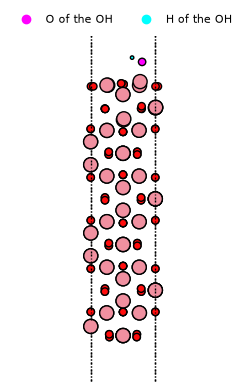

In [10]:
slab_relaxed = clean_after
finder = AdsorbateSiteFinder(AseAtomsAdaptor.get_structure(slab_relaxed))
found = finder.find_adsorption_sites()

normal = np.cross(slab_relaxed.cell[0], slab_relaxed.cell[1])
normal = normal / np.linalg.norm(normal)
z_top = slab_relaxed.positions[:, 2].max()
symbols = slab_relaxed.get_chemical_symbols()

rows = []
for k, site in enumerate(found["ontop"]):
    below = np.array([site - 2.0 * normal])
    distances = get_distances(below, slab_relaxed.positions, cell=slab_relaxed.cell, pbc=True)[1][0]
    j = int(np.argmin(distances))
    rows.append({"site": k, "atom under it": j, "element": symbols[j],
                 "distance to that atom (Å)": round(float(distances[j]), 3),
                 "depth below the highest atom (Å)": round(float(z_top - slab_relaxed.positions[j, 2]), 3)})
sites = pd.DataFrame(rows)
chosen = sites[(sites["element"] == "Co") & (sites["depth below the highest atom (Å)"] <= 1.5)].iloc[0]
site_position = found["ontop"][int(chosen["site"])]

print("Sites the finder returned, by type")
print({kind: len(found[kind]) for kind in ("ontop", "bridge", "hollow")})
print("Atoms within 0.9 Å of the highest atom, the window of the finder")
print(int((z_top - slab_relaxed.positions[:, 2] <= 0.9).sum()))
print("Atoms of the relaxed slab in the top 1.5 Å, by element")
top_atoms = [symbols[i] for i in range(len(slab_relaxed)) if z_top - slab_relaxed.positions[i, 2] <= 1.5]
print({el: top_atoms.count(el) for el in sorted(set(top_atoms))})
print()
print("The on-top sites and the atom under each")
print(sites.to_string(index=False))
print()
print("Site taken")
print(int(chosen["site"]))
print("Position of the O of the OH (Å)")
print(site_position.round(3))

slab_oh = slab_relaxed.copy()
slab_oh += Atoms("OH", positions=[site_position, site_position + 0.97 * normal])
OH_DIR = WORK / "slab_OH"
OH_DIR.mkdir(exist_ok=True)
write(OH_DIR / "POSCAR", slab_oh, format="vasp", direct=True, sort=True)

print()
print("Atoms in the structure")
print(len(slab_oh))
print("Composition")
print(slab_oh.get_chemical_formula())

run_mlip(["optimize", "run",
          "--structure", str(OH_DIR / "POSCAR"),
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "bfgs",
          "--max-steps", "200"], "slab " + FACE + " with *OH")

oh_after = read(OH_DIR / "opt_final.vasp")
oh_stage = last_stage(OH_DIR)
oh_curve = pd.read_csv(OH_DIR / "opt_convergence.csv")
e_slab_oh = oh_stage["results"]["final_energy_eV"]

def oh_geometry(atoms):
    # Where the OH of a relaxed slab sits: its O, the Co under it, and how the OH is tilted.
    sym = atoms.get_chemical_symbols()
    h = sym.index("H")
    o_all = [i for i, s in enumerate(sym) if s == "O"]
    o = o_all[int(np.argmin(atoms.get_distances(h, o_all, mic=True)))]
    co_all = [i for i, s in enumerate(sym) if s == "Co"]
    co_d = np.sort(atoms.get_distances(o, co_all, mic=True))
    v = atoms.get_distances(o, [h], mic=True, vector=True)[0]
    return {"O to its nearest Co (Å)": float(co_d[0]),
            "Co atoms within 2.6 Å of that O": int((co_d < 2.6).sum()),
            "O to H (Å)": float(np.linalg.norm(v)),
            "angle of O to H from the z axis (°)": float(np.degrees(np.arccos(v[2] / np.linalg.norm(v)))),
            "H to the nearest other O (Å)": float(
                atoms.get_distances(h, [i for i in o_all if i != o], mic=True).min())}


geometry = oh_geometry(oh_after)

print()
print("Status of the last stage in the run record")
print(oh_stage["status"])
print("converged, from the last stage's results")
print(oh_stage["results"]["converged"])
print("Steps")
print(oh_stage["steps"])
print("Final largest force (eV/Å)")
print(round(oh_stage["results"]["final_fmax_eV_per_A"], 4))
print("Energy at step 0 (eV)")
print(round(float(oh_curve["energy(eV)"].iloc[0]), 3))
print("Final energy (eV)")
print(round(e_slab_oh, 3))
print()
for name, value in geometry.items():
    print(name)
    print(round(value, 3) if isinstance(value, float) else value)

h_oh = oh_after.get_chemical_symbols().index("H")
o_all = [i for i, s in enumerate(oh_after.get_chemical_symbols()) if s == "O"]
o_oh = o_all[int(np.argmin(oh_after.get_distances(h_oh, o_all, mic=True)))]
atom_colors = [tuple(c) for c in jmol_colors[oh_after.numbers]]
atom_colors[o_oh] = "magenta"
atom_colors[h_oh] = "cyan"

view = oh_after.copy()
view.rotate(90, "z", rotate_cell=True)

fig, ax = plt.subplots(figsize=(3.2, 4.5))
plot_atoms(view, ax, radii=0.5, rotation="-90x", colors=atom_colors)
ax.set_ylim(oh_after.positions[:, 2].min() - 3, oh_after.positions[:, 2].max() + 3)
ax.legend(handles=[plt.Line2D([], [], marker="o", linestyle="", color="magenta", label="O of the OH"),
                   plt.Line2D([], [], marker="o", linestyle="", color="cyan", label="H of the OH")],
          loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8, frameon=False)
plt.show()

### 4a. The same relaxation twice more

- The relaxation of the slab with `*OH` is run two more times from the same `POSCAR`, into `work/slab_OH_b/` and `work/slab_OH_c/`, with the same command
    - `mlip optimize run --structure work/slab_OH_b/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200`
    - The question is whether the number of the section on the adsorption energy is one number or one draw of several: the file is the same, the command is the same, and the command's option list has no seed
- `max(list) - min(list)` is the spread of a list of numbers, and the table prints the steps, the `converged` label, the final energy and the tilt of the OH for the three runs
    - The two repeats run with `show=False`, as the repeats of module 10 did, so they print nothing but this table
- In the saved run:
    - All three runs converged, in 45, 50 and 48 steps, at final energies of −998.9094, −998.9138 and −998.9125 eV, a spread of 0.0045 eV, with the angle of the O to H direction from the z axis at 66.8°, 70.3° and 68.5°
    - So the same command on the same file did not return the same end point in all three runs, and the third decimal of any energy computed from this structure is not reproducible; the value of the section on the adsorption energy is quoted to two decimals
    - The page does not say why the runs differ
- This is canon `K1` at one more level: a `converged` label says the force target was reached, and it does not say that another run would end at the same energy

In [11]:
OH_ENERGIES = [e_slab_oh]
repeat_rows = [{"run": "the run above", "steps": oh_stage["steps"],
                "converged": oh_stage["results"]["converged"],
                "final energy (eV)": round(e_slab_oh, 4),
                "angle of O to H from the z axis (°)": round(geometry["angle of O to H from the z axis (°)"], 1)}]

for tag in ("b", "c"):
    folder = WORK / ("slab_OH_" + tag)
    folder.mkdir(exist_ok=True)
    shutil.copy(OH_DIR / "POSCAR", folder / "POSCAR")
    run_mlip(["optimize", "run",
              "--structure", str(folder / "POSCAR"),
              "--mlip", "mace",
              "--device", "cpu",
              "--fmax", "0.05",
              "--optimizer", "bfgs",
              "--max-steps", "200"], "slab with *OH, repeat " + tag, show=False)
    stage_here = last_stage(folder)
    OH_ENERGIES.append(stage_here["results"]["final_energy_eV"])
    repeat_rows.append({"run": "repeat " + tag, "steps": stage_here["steps"],
                        "converged": stage_here["results"]["converged"],
                        "final energy (eV)": round(stage_here["results"]["final_energy_eV"], 4),
                        "angle of O to H from the z axis (°)": round(
                            oh_geometry(read(folder / "opt_final.vasp"))["angle of O to H from the z axis (°)"], 1)})

print("The relaxation of the slab with *OH, three times from the same file")
print(pd.DataFrame(repeat_rows).to_string(index=False))
print()
print("Largest minus smallest final energy (eV)")
print(round(max(OH_ENERGIES) - min(OH_ENERGIES), 4))

The relaxation of the slab with *OH, three times from the same file
          run  steps  converged  final energy (eV)  angle of O to H from the z axis (°)
the run above     45       True          -998.9094                                 66.8
     repeat b     50       True          -998.9138                                 70.3
     repeat c     48       True          -998.9125                                 68.5

Largest minus smallest final energy (eV)
0.0045


## 5. Adsorption energy

- `E_ads(*OH) = E(slab+OH) − E(slab) − (E(H2O) − ½ E(H2))`, with every term relaxed at the same settings
    - `E(slab+OH)` and `E(slab)` are the two relaxations above, `E(H2O)` and `E(H2)` are two molecules in 12 Å boxes from `molecule_in_box`, relaxed here with the same command, `--fmax 0.05` and `--optimizer bfgs`, canon `C4`
    - The reference `E(H2O) − ½ E(H2)` stands for an OH made from one water molecule, which releases half an H2 molecule (`H2O + * → *OH + ½ H2`), and that is the form the computational hydrogen electrode builds on, reading list Part A, entry 2, where the reasoning is; this notebook computes this one energy difference and does not apply that method any further
    - The project builds its electrochemical anchor from `H2O` and `H2` too, `E-p4`, and the reason it gives for not using `O2` is that all three of its models fail an `O2` gate, while `H2` and gas `H2O` are well described; that statement is about the project's models and not about the model of this notebook
- The value is a teaching value, and the page can say what it is the value of
    - One face, `r1`, one site, the first on-top site over a surface Co, one orientation, one thickness of slab, one model, no magnetic moments given and no solvent
    - `OH` sits on one side of a slab whose two sides were equal before, and MLIPs have no dipole correction, as entry `S5` of `DECISIONS.md` notes; this notebook does not test whether that matters
    - The page prints no DFT value and no literature value for this quantity, so it is compared with neither
- `molecule_in_box("H2O")` and `molecule_in_box("H2")` are the helpers of module 05, and each is written to a `POSCAR` in its own folder
- In the table:
    - One row per term, with its `converged` label, its steps and its energy, canon `K1`
    - A term that did not converge would make the result not a result, and all four are read from the run records before the sum is taken
- In the saved run:
    - All four terms converged, in 45 steps for the slab with `*OH`, 9 for the slab, 2 for H2O and 1 for H2
    - `E(slab+OH) − E(slab)` is −9.5449 eV and the reference `E(H2O) − ½ E(H2)` is −10.898 eV, so `E_ads(*OH)` is +1.353 eV
    - With each of the three relaxations of the slab with `*OH` of the section on the same relaxation twice more, `E_ads(*OH)` is 1.353, 1.349 and 1.350 eV, a spread of 0.0045 eV, so the value is quoted to two decimals, +1.35 eV
    - A positive value means that, with this model on this site, making `*OH` on the slab from one water molecule and releasing half an H2 molecule costs energy; it does not mean that OH does not bind to the slab, because the reference is not the free OH radical
    - The page does not compare 1.353 eV with the first-step energy of the onboarding deck named in `README.md`, 0.62 eV on slide 4, because that one is for another face, Co3O4(111), and the source line of the slide says only that it is an internal calculation and does not name the model

In [12]:
TERMS = {}
for name in ("H2O", "H2"):
    folder = WORK / name
    folder.mkdir(exist_ok=True)
    write(folder / "POSCAR", molecule_in_box(name), format="vasp", direct=True, sort=True)
    run_mlip(["optimize", "run",
              "--structure", str(folder / "POSCAR"),
              "--mlip", "mace",
              "--device", "cpu",
              "--fmax", "0.05",
              "--optimizer", "bfgs",
              "--max-steps", "200"], name + " in a box", show=(name == "H2O"))
    TERMS[name] = last_stage(folder)

terms = {"E(slab+OH)": oh_stage, "E(slab)": clean_stage, "E(H2O)": TERMS["H2O"], "E(H2)": TERMS["H2"]}
rows = [{"term": label, "converged": st["results"]["converged"], "steps": st["steps"],
         "energy (eV)": round(st["results"]["final_energy_eV"], 4)} for label, st in terms.items()]

e_h2o = TERMS["H2O"]["results"]["final_energy_eV"]
e_h2 = TERMS["H2"]["results"]["final_energy_eV"]
reference = e_h2o - 0.5 * e_h2
e_ads = e_slab_oh - e_clean - reference
all_converged = all(st["results"]["converged"] for st in terms.values())

print()
print("The four terms of E_ads, each relaxed at 0.05 eV/Å with bfgs")
print(pd.DataFrame(rows).to_string(index=False))
print()
print("All four converged")
print(all_converged)
print("Reference E(H2O) minus half E(H2) (eV)")
print(round(reference, 4))
print("E(slab+OH) minus E(slab) (eV)")
print(round(e_slab_oh - e_clean, 4))
print("E_ads(*OH) (eV)")
print(round(e_ads, 3))

e_ads_each = [e - e_clean - reference for e in OH_ENERGIES]
print()
print("E_ads(*OH) from each of the three relaxations of the slab with *OH (eV)")
print([round(x, 3) for x in e_ads_each])
print("Largest minus smallest (eV)")
print(round(max(e_ads_each) - min(e_ads_each), 4))

Command, as you would type it in the terminal
mlip optimize run --structure work/H2O/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
7.9



The four terms of E_ads, each relaxed at 0.05 eV/Å with bfgs
      term  converged  steps  energy (eV)
E(slab+OH)       True     45    -998.9094
   E(slab)       True      9    -989.3644
    E(H2O)       True      2     -14.1602
     E(H2)       True      1      -6.5245

All four converged
True
Reference E(H2O) minus half E(H2) (eV)
-10.898
E(slab+OH) minus E(slab) (eV)
-9.5449
E_ads(*OH) (eV)
1.353

E_ads(*OH) from each of the three relaxations of the slab with *OH (eV)
[1.353, 1.349, 1.35]
Largest minus smallest (eV)
0.0045


## 6. Write it up

- A result is written with everything that makes it reproducible, and the sentence below is filled from the variables of this notebook, so that a number and its settings cannot drift apart
    - The model, the force target, the optimizer and the `converged` labels, canon `C1`, `C2`, `K1`
    - The bulk the slab came from, and the face, with the warning about the pymatgen version
    - The reference, and what the number is the value of
- The provenance block of the run record is printed too, which is where the version numbers of a methods section come from
- `textwrap.fill(text, width=100)` wraps a long text into lines of at most 100 characters, and `format(x, ".2f")` writes a number with two decimals
- What the sentence does not say, on purpose
    - That `E_ads` is the adsorption energy of OH on Co3O4(1 0 0): it is this model's number on one face, one site and one orientation, and the claim needs the project's settings and a comparison with DFT, which this page does not have
    - Which face is exposed: that needs the surface energies of all faces as lines in `μ_O`, which this page does not compute
- In the last table:
    - The seconds each command of this notebook took, in the order they ran

In [13]:
provenance = json.loads((OH_DIR / "mliprun_run.json").read_text())["provenance"]
steps = {"slab": clean_stage["steps"], "slab with OH": oh_stage["steps"]}
labels = {label: ("converged" if st["results"]["converged"] else "not converged") for label, st in terms.items()}

paragraph = (
    "OH on Co3O4(1 0 0), face " + FACE + " of the symmetric Reuter-Scheffler slabs of the project's script "
    "gen_rs_slabs.py (" + str(len(slab)) + " atoms, " + format(thickness, ".1f") + " Å thick, all atoms free), "
    "cleaved from a bulk relaxed with the same model (a = " + format(a_relaxed, ".3f") + " Å), "
    "pymatgen " + pmg_core.__version__ + ", with OH placed upright on the first on-top site over a surface Co, "
    "relaxed with MACE-MP-0 through mliprun " + provenance["mliprun_version"] + " to fmax 0.05 eV/Å with BFGS "
    "(slab " + str(steps["slab"]) + " steps, " + labels["E(slab)"] + "; slab with OH " + str(steps["slab with OH"])
    + " steps, " + labels["E(slab+OH)"] + "), gives E_ads(*OH) = " + format(e_ads, ".2f") + " eV against "
    "H2O − ½ H2 relaxed at the same settings (" + labels["E(H2O)"] + ", " + labels["E(H2)"] + "). It is a "
    "teaching value on one face, one site and one orientation, not compared with DFT.")

print("Sentence for a lab note")
print(textwrap.fill(paragraph, width=100))
print()
print("Model the run used")
print(provenance["mlip_model"])
print("Package behind that model, and its version")
print([provenance["mlip_package"]["name"], provenance["mlip_package"]["version"]])
print("mliprun version")
print(provenance["mliprun_version"])
print("ASE version")
print(provenance["ase_version"])
print("Device asked for, and the device used")
print([provenance["device_requested"], provenance["device_resolved"]])
print()
print("Seconds each command took, in the order they ran")
print(pd.DataFrame(TIMES).to_string(index=False))
print("Seconds in all of them")
print(round(sum(t["seconds"] for t in TIMES), 1))

Sentence for a lab note
OH on Co3O4(1 0 0), face r1 of the symmetric Reuter-Scheffler slabs of the project's script
gen_rs_slabs.py (166 atoms, 22.7 Å thick, all atoms free), cleaved from a bulk relaxed with the same
model (a = 8.169 Å), pymatgen 2026.8.30, with OH placed upright on the first on-top site over a
surface Co, relaxed with MACE-MP-0 through mliprun 0.4.0 to fmax 0.05 eV/Å with BFGS (slab 9 steps,
converged; slab with OH 45 steps, converged), gives E_ads(*OH) = 1.35 eV against H2O − ½ H2 relaxed
at the same settings (converged, converged). It is a teaching value on one face, one site and one
orientation, not compared with DFT.

Model the run used
mace
Package behind that model, and its version
['mace-torch', '0.3.16']
mliprun version
0.4.0
ASE version
3.29.0
Device asked for, and the device used
['cpu', 'cpu']

Seconds each command took, in the order they ran
                      command  seconds
   bulk Co3O4, cell and atoms      8.8
        bulk CoOOH, as served      4.6

## Check yourself

1. You run `gen_rs_slabs.py` on your own computer and your pymatgen is newer than the one canon `S1` pins.
   A colleague in the group has a slab labelled `r2` for the same Miller index. Can you compare your `r2` with theirs by the label?
2. A reviewer asks whether the number at the end of section 5 is the adsorption energy of OH on Co3O4(1 0 0). What do you answer, and what would you have to do to be able to say yes?
3. The relaxation of CoOOH from the file as served ends with `converged` true and the H atom midway between two O atoms. Do you report that as the relaxed bulk, and what do you do?

<details>
<summary>Answers</summary>

- No. The script prints a warning on a newer pymatgen that the set of cuts and the numbering of faces may differ from production, and the label `r<k>` is only a position in the list the script made on that run. Compare the face key, the layers of `element[neighbours]` of the audit table, and not the label; or run in an environment with the pinned version, which a project provides
- Not yet, and not from this page. It is one face of four, one site, one orientation and one slab thickness, with a model whose bulk lattice was compared with other models of the project and not with DFT, canon `A1`, `A2`, `E-p3`. To say yes you would need the face to be the exposed one, which needs the surface energies of all faces as lines in `μ_O`, a site and orientation search, a thickness that meets the project's rule once it is decided, and a comparison with DFT at the project's level of theory
- No. A `converged` label means the force target was reached, and it does not say the structure is the lowest one: this page's second run from a start with the H moved ended 0.0885 eV lower in energy and at 1.006 and 1.668 Å from its two O atoms. You report the start with the result, try more than one start, and take the lowest converged one while saying how many starts were tried

</details>